### this script checks how first author and last author distributed across income groups

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from random import sample
from matplotlib.lines import Line2D

In [5]:
author_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/authors_noalpha_int.pkl"
pub_path="../../data/dropbox/LaborDivision/Data/deriveddata/pubs_noalpha_int/pubs_noalpha_int.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'

In [3]:
author_df=pd.read_pickle(author_path)

In [4]:
pub_df=pd.read_pickle(pub_path)

In [8]:
ingroup_df=pd.read_csv(ingroup_path)[['Code','ST']].drop_duplicates()
#ingroupdict = dict(zip(ingroup_df['Code'],ingroup_df['ingroup_08-20']))

In [11]:
ingroup_df.head()

,Code,ST
0,AFG,Others
1,ALB,Lagging
2,DZA,Lagging
3,AND,Others
4,AGO,Lagging


In [10]:
author_df.head()

,id,year,dis,cluster_id,role,Code
3,29768070,2008,51,20009795,F,JPN
4,29768070,2008,51,29411586,M,JPN
5,29768070,2008,51,37122561,M,CHN
6,29768070,2008,51,1221298,M,JPN
7,29768070,2008,51,38679117,L,JPN


In [12]:
author_df=author_df.merge(ingroup_df,on='Code',how='left')

In [14]:
author_df=author_df.replace(to_replace={'ST':{'Others':'Lagging'}})

#### calculate the general distribution of the last author and first author

In [15]:
def norm(df):
    df = df.groupby(['year','ST']).size(
    ).reset_index(name='count'
                 ).pivot(index='year',columns='ST',values='count')
    df=df.div(df.sum(axis=1), axis=0).reset_index()
    df = df.melt(id_vars='year', var_name='ST', value_name='count')
    return df

In [16]:
first_df=author_df[author_df.role=='F']
first_df=norm(first_df)

In [17]:
last_df=author_df[author_df.role=='L']
last_df=norm(last_df)

In [18]:
middle_df=author_df[author_df.role=='M']
middle_df=norm(middle_df)

In [19]:
def plot(df, title, ax):
    color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
    sns.lineplot(x='year',y='count',hue='ST',data=df,ax=ax,legend=False,
                palette=color,hue_order=['Advanced','Proficient','Developing','Lagging'])
    ax.set_title(title,fontsize=12)
    ax.set_ylim(0,1)
    ax.set_xlabel("")
    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.set_ylabel("")
    return ax

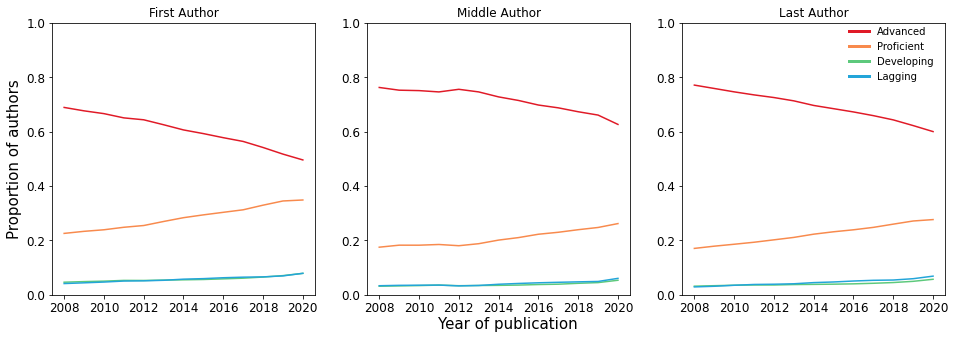

In [24]:
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(16,5))
ax[0]=plot(first_df,'First Author', ax[0])
ax[0].set_ylabel("Proportion of authors",fontsize=15)

ax[1]=plot(middle_df,'Middle Author', ax[1])
ax[2]=plot(last_df,'Last Author',ax[2])

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['Advanced', 'Proficient', 'Developing','Lagging']
ax[2].legend(lines, labels,loc=(0.62,0.77),frameon=False)
fig.text(x=0.46,y=0.03,s="Year of publication",fontsize=15)

plt.savefig("../../data/dropbox/LaborDivision/figs/author_distribution.pdf",bbox_inches='tight')

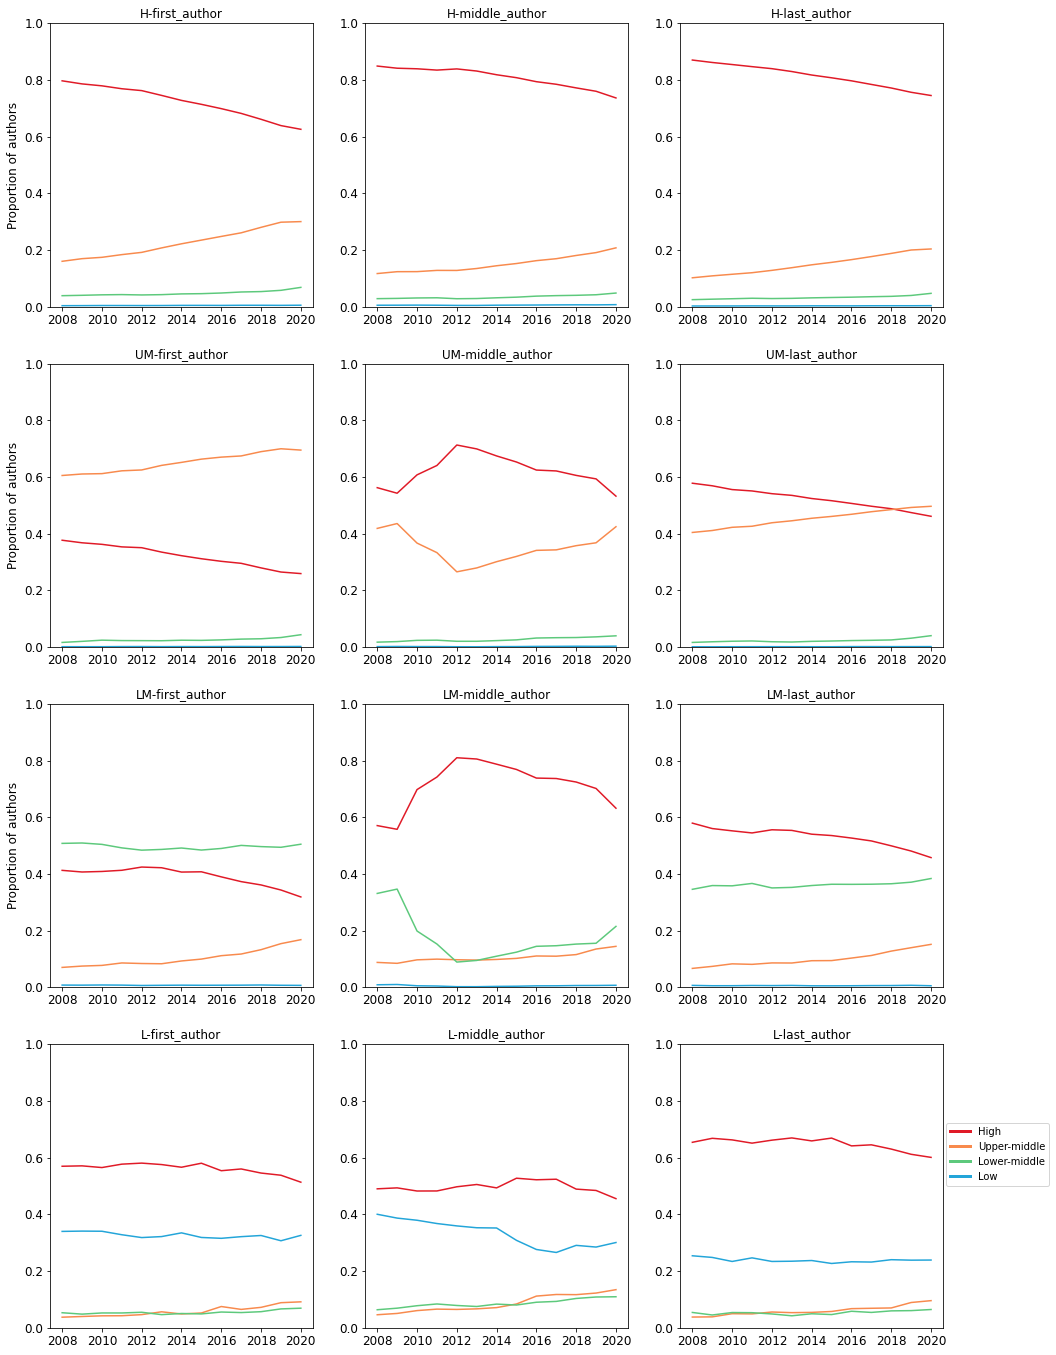

In [99]:
gs=['H','UM','LM','L']
titles=['High','Upper Middle','Low Middle','Low']
fig, ax = plt.subplots(nrows=4,ncols=3,figsize=(16,24))
for index, g in enumerate(gs):
    gin = author_df[author_df['ingroup']==g]['id'].unique()
    gdf=author_df[author_df['id'].isin(gin)]
    
    first_df=gdf[gdf.role=='F']
    first_df=norm(first_df)
    ax[index][0]=plot(first_df,'',ax[index][0])
    ax[index][0].set_title("{}-{}".format(g,'first_author'))
    
    middle_df=gdf[gdf.role=='M']
    middle_df=norm(middle_df)
    ax[index][1]=plot(middle_df,'',ax[index][1])
    ax[index][1].set_title("{}-{}".format(g,'middle_author'))
    
    last_df=gdf[gdf.role=='L']
    last_df=norm(last_df)
    ax[index][2]=plot(last_df,'',ax[index][2])
    ax[index][2].set_title("{}-{}".format(g,'last_author'))
    
colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['High', 'Upper-middle', 'Lower-middle','Low']
plt.legend(lines, labels,loc=(1.01,0.5))
ax[0][0].set_ylabel('Proportion of authors',fontsize=12)
ax[1][0].set_ylabel('Proportion of authors',fontsize=12)
ax[2][0].set_ylabel('Proportion of authors',fontsize=12)
plt.savefig("../../data/dropbox/LaborDivision/figs/author_distribution_condition_overtime.pdf",bbox_inches='tight')

In [26]:
author_df.head()

,id,year,dis,cluster_id,role,Code,ST
0,29768070,2008,51,20009795,F,JPN,Advanced
1,29768070,2008,51,29411586,M,JPN,Advanced
2,29768070,2008,51,37122561,M,CHN,Proficient
3,29768070,2008,51,1221298,M,JPN,Advanced
4,29768070,2008,51,38679117,L,JPN,Advanced


In [33]:
def norm2(df):
    dfnorm = df.groupby(['role','ST']).size().reset_index(name='count')
    dfnorm = dfnorm.pivot(index='role',columns='ST',values='count')
    dfnorm=dfnorm.reindex(['L','M','F'])
    dfnorm=dfnorm[['Advanced','Proficient','Developing','Lagging']]
    dfnorm=dfnorm.div(dfnorm.sum(axis=1), axis=0)
    return dfnorm

In [34]:

def plot_stackedbar(df,ax):
    
    hvalue=df.loc[:,'Advanced']
    umvalue=df.loc[:,'Proficient']
    lmvalue=df.loc[:,'Developing']
    lvalue=df.loc[:,'Lagging']
    
    ypos=[0.3,1.2,2.1]
    ylabel=['Last','Middle','First']
    ax.barh(ypos,hvalue,color='#E01A27',height=0.6)
    ax.barh(ypos,umvalue,color='#F88A4D',left=hvalue,height=0.6)
    ax.barh(ypos,lmvalue,color='#5DC97C', left=hvalue+umvalue,height=0.6)
    ax.barh(ypos,lvalue,color='#23A5D9', left=hvalue+umvalue+lmvalue,height=0.6)
    ax.set_yticks(ypos)
    ax.set_yticklabels(ylabel,fontsize=12)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='both', labelsize=12)
    
    return ax

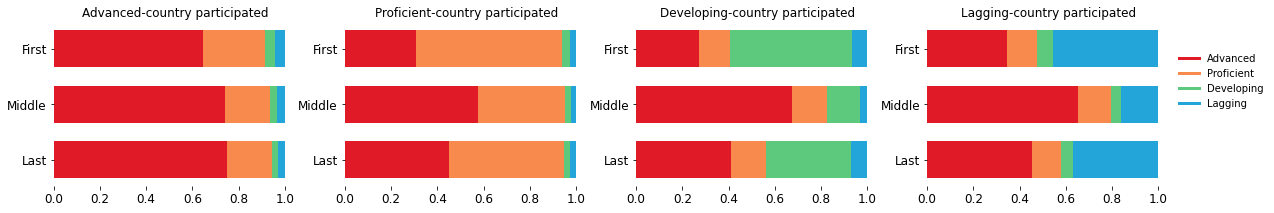

In [35]:
gs=['Advanced','Proficient','Developing','Lagging']
fig, ax = plt.subplots(nrows=1,ncols=4,figsize=(20,3))
for index, g in enumerate(gs):
    gin = author_df[author_df['ST']==g]['id'].unique()
    gdf=author_df[author_df['id'].isin(gin)]
    
    dfnorm=norm2(gdf)
    ax[index]=plot_stackedbar(dfnorm,ax[index])
    ax[index].set_title("{}-{} {}".format(gs[index],'country','participated'))
    
colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
ax[3].legend(lines, gs,loc=(1.02,0.45),frameon=False)
plt.savefig("../../data/dropbox/LaborDivision/figs/author_distribution_condition.pdf",bbox_inches='tight')